# Get to Know a Dataset: Gramscii European Open Data Catalogue

This notebook is a guided tour of the [Gramscii European Open Data Catalogue](https://registry.opendata.aws/gramscii-european-open-data-catalogue) dataset. More usage examples, tutorials, and documentation for this dataset and others can be found at the [Registry of Open Data on AWS](https://registry.opendata.aws/).

The catalogue describes 78,150 public datasets from 34 European, international and Italian providers: ISTAT, Eurostat, INSEE, the OECD, the ILO, the ECB, the BIS, the Deutsche Bundesbank, the FAO, France's national open data portal, Italian cities and regions, and their urban plans. For every dataset it records what the dataset is, how it is structured, which codes and labels it uses in each published language, where it can be read, and under which terms. It holds metadata only: the values stay with the original provider.

### Q: How have you organized your dataset? Help us understand the key prefix structure of your S3 bucket.

The bucket has one top-level prefix, `catalogue/`, which holds:

1. `manifest.json`, which describes the release: when the snapshot was taken, the archive it was written from, every table's rows and columns, and every file's size and SHA-256.
2. One prefix per table, named after the catalogue's database table: `opendata_catalog/`, `opendata_structures/`, `opendata_terms/` and so on.
3. Inside every table keyed by provider, one Hive-style partition per provider, `provider=<id>/`, holding that provider's rows in `data_0.parquet`. The verbatim provider responses in `opendata_native_objects/` are one file, addressed by their SHA-256.

Each release replaces the previous one, so `manifest.json` is the place to start.

In [1]:
# This notebook requires the following additional libraries
# (please install using the preferred method for your environment, e.g. pip, conda):
#
# boto3 >= 1.40
# duckdb >= 1.5
# pandas >= 2.3
# matplotlib >= 3.10

# Import the libraries required for this notebook
# Built-ins
import json
from pprint import pprint
# Installed libraries
import boto3
import duckdb
import matplotlib.pyplot as plt
from botocore import UNSIGNED
from botocore.config import Config

First we define the location of the dataset, create an S3 client that does not sign its requests (the bucket is public, so no AWS account is needed), and list the top-level prefix.

In [2]:
# Location of the S3 bucket for this dataset
bucket = "gramscii-european-open-data-catalogue"
region = "eu-central-1"

s3 = boto3.client("s3", region_name=region, config=Config(signature_version=UNSIGNED))

# Print the top-level prefixes
for item in s3.list_objects_v2(Bucket=bucket, Delimiter="/")["CommonPrefixes"]:
    print(item["Prefix"])

catalogue/


Inside `catalogue/` there is one prefix per table, beside the manifest.

In [3]:
# List the tables of the catalogue
for item in s3.list_objects_v2(Bucket=bucket, Prefix="catalogue/", Delimiter="/")["CommonPrefixes"]:
    print(item["Prefix"])

catalogue/opendata_catalog/
catalogue/opendata_document_codes/
catalogue/opendata_documents/
catalogue/opendata_held_codes/
catalogue/opendata_meta_reports/
catalogue/opendata_native_bindings/
catalogue/opendata_native_exclusions/
catalogue/opendata_native_objects/
catalogue/opendata_structure_dims/
catalogue/opendata_structures/
catalogue/opendata_terms/


The manifest says when the snapshot was taken, how many rows each table holds, and which columns it has.

In [4]:
# Read the release manifest
with s3.get_object(Bucket=bucket, Key="catalogue/manifest.json")["Body"] as body:
    manifest = json.load(body)

print("Snapshot taken at", manifest["taken_at"])
for name, table in manifest["tables"].items():
    print(f"{name:28} {table['rows']:>10,} rows, partitioned by {table['partition']}")

Snapshot taken at 2026-11-11T19:00:06.024185+00:00
opendata_catalog                 78,150 rows, partitioned by provider
opendata_structures              78,150 rows, partitioned by provider
opendata_structure_dims          93,951 rows, partitioned by provider
opendata_terms                3,949,157 rows, partitioned by provider
opendata_labels                       0 rows, partitioned by provider
opendata_meta_reports             1,293 rows, partitioned by provider
opendata_document_codes          85,718 rows, partitioned by provider
opendata_documents               30,069 rows, partitioned by provider
opendata_native_objects          21,556 rows, partitioned by None
opendata_native_bindings         12,643 rows, partitioned by provider
opendata_native_exclusions      257,520 rows, partitioned by provider
opendata_held_codes             117,541 rows, partitioned by provider


In [5]:
# Each table keyed by provider holds one partition per provider
for item in s3.list_objects_v2(Bucket=bucket, Prefix="catalogue/opendata_catalog/", Delimiter="/")["CommonPrefixes"][:10]:
    print(item["Prefix"])

catalogue/opendata_catalog/provider=bis/
catalogue/opendata_catalog/provider=bologna/
catalogue/opendata_catalog/provider=bolzano-puc/
catalogue/opendata_catalog/provider=bundesbank/
catalogue/opendata_catalog/provider=cruscotto/
catalogue/opendata_catalog/provider=datagouv/
catalogue/opendata_catalog/provider=datigov-sardegna/
catalogue/opendata_catalog/provider=dvns/
catalogue/opendata_catalog/provider=ec-empl/
catalogue/opendata_catalog/provider=ec-grow/


### Q: What data formats are present in your dataset? What kinds of data are stored using these formats? Can you give any advice for how to work with these data types?

Every table is stored as [Apache Parquet](https://parquet.apache.org/), compressed with Zstandard, and partitioned the Hive way by `provider`. We chose Parquet because it is columnar: a reader that needs three columns of one provider reads only those bytes, over HTTP, without downloading the catalogue. Most tools read it directly: [DuckDB](https://duckdb.org), PyArrow and pandas, Apache Spark, and [Amazon Athena](https://aws.amazon.com/athena/).

Columns keep the types of the catalogue's database: text, booleans, integers, dates, timestamps (stored as UTC instants), lists of text, binary, and JSON. The JSON columns (`names`, `sources`, `dimensions`, `spatial` and others) hold nested metadata exactly as each provider described it, so their shape differs between providers: read them with JSON functions rather than expecting one schema.

In this notebook we use DuckDB, which reads the Parquet files straight from S3 and answers SQL. The `httpfs` extension gives it S3 access; the bucket is public, so no credentials are needed.

In [6]:
# A DuckDB connection that reads the bucket anonymously
con = duckdb.connect()
con.execute("INSTALL httpfs")
con.execute("LOAD httpfs")
con.execute(f"SET s3_region = '{region}'")

root = f"s3://{bucket}/catalogue"

def table(name):
    """The SQL source of one catalogue table, with its provider partitions as a column."""
    return f"read_parquet('{root}/{name}/*/*.parquet', hive_partitioning = true)"

In [7]:
# The columns and types of the main table
con.sql(f"DESCRIBE SELECT * FROM {table('opendata_catalog')}").df()

,column_name,column_type,null,key,default,extra
0,dataset_id,VARCHAR,YES,None,None,None
1,version,VARCHAR,YES,None,None,None
2,title,VARCHAR,YES,None,None,None
3,title_en,VARCHAR,YES,None,None,None
4,description,VARCHAR,YES,None,None,None
5,category_path,VARCHAR,YES,None,None,None
6,structure_id,VARCHAR,YES,None,None,None
7,territorial_level,VARCHAR,YES,None,None,None
8,last_update,VARCHAR,YES,None,None,None
9,active,BOOLEAN,YES,None,None,None


### Q: Can you show us an example of downloading and loading data from your dataset?

Let us load the catalogue entries of one provider, ISTAT, the Italian national statistical institute. Because the table is partitioned by provider, DuckDB reads only the `provider=istat` files.

Not every dataset declares the period its data cover: where the provider publishes none, `period_start` and `period_end` are empty. We keep all of ISTAT's datasets and preview ten that declare a period. The two columns hold ISO dates as text, as the providers publish them.

In [8]:
istat = con.sql(f"""
    SELECT dataset_id, title, title_en, period_start, period_end, licence
    FROM {table('opendata_catalog')}
    WHERE provider = 'istat'
    ORDER BY dataset_id
""").df()

dated = istat[istat["period_start"].notna()]
print(len(istat), "ISTAT datasets,", len(dated), "of them with a declared time period")
dated.head(10)

4526 ISTAT datasets, 3797 of them with a declared time period


,dataset_id,title,title_en,period_start,period_end,licence
93,111_263,Fiducia delle imprese manifatturiere,Business confidence in the manufacturing sector,1985-10-01,2026-09-30,CC BY 4.0
95,111_263_DF_DCSC_FIDIMPRMAN_10,"Clima, saldi e frequenze mensili grezzi - rip.","Monthly raw climate, balances and frequency - ...",1986-01-01,2015-02-28,CC BY 4.0
96,111_263_DF_DCSC_FIDIMPRMAN_11,"Clima, saldi e frequenze mensili grezzi per Ateco","Monthly raw climate, balances and frequency by...",1986-01-01,2015-02-28,CC BY 4.0
97,111_263_DF_DCSC_FIDIMPRMAN_12,Saldi e frequenze mensili grezzi per classe di...,Monthly raw balances and frequency by size cla...,1986-01-01,2015-02-28,CC BY 4.0
98,111_263_DF_DCSC_FIDIMPRMAN_13,Modulo trimestrale imprese esportatrici e capa...,Quarterly seasonally adjusted export and capac...,2000-01-01,2014-12-31,CC BY 4.0
99,111_263_DF_DCSC_FIDIMPRMAN_14,Modulo trimestrale imprese esportatrici e capa...,Quarterly raw export and capacity utilisation ...,1985-10-01,2014-12-31,CC BY 4.0
100,111_263_DF_DCSC_FIDIMPRMAN_15,Modulo trimestrale imprese esportatrici e capa...,Quarterly raw export and capacity utilisation ...,1985-10-01,2023-12-31,CC BY 4.0
101,111_263_DF_DCSC_FIDIMPRMAN_16,Modulo trimestrale imprese esportatrici e capa...,Quarterly raw export and capacity utilisation ...,1985-10-01,2014-12-31,CC BY 4.0
102,111_263_DF_DCSC_FIDIMPRMAN_17,Clima e saldi mensili destagionalizzati,Monthly seasonally adjusted climate and balances,2000-01-01,2026-09-30,CC BY 4.0
103,111_263_DF_DCSC_FIDIMPRMAN_18,"Clima, saldi e frequenze mensili grezzi - rip.","Monthly raw climate, balances and frequency - ...",1986-01-01,2026-09-30,CC BY 4.0


One dataset's structure tells which dimensions its observations are classified by. Each dimension draws its codes from a code list, and `opendata_terms` names every code in each published language. Here we take the first ISTAT dataset with a structure and list its dimensions.

In [9]:
dataset = con.sql(f"""
    SELECT c.dataset_id, c.title, c.structure_id
    FROM {table('opendata_catalog')} c
    WHERE c.provider = 'istat' AND c.structure_available
    ORDER BY c.dataset_id
    LIMIT 1
""").fetchall()[0]
print(dataset)

con.sql(f"""
    SELECT dimension_id, concept_id, codelist_scope
    FROM {table('opendata_structure_dims')}
    WHERE provider = 'istat' AND structure_id = $structure
    ORDER BY dimension_id
""", params={"structure": dataset[2]}).df()

('101_1015', 'Coltivazioni', 'DCSP_COLTIVAZIONI')


,dimension_id,concept_id,codelist_scope
0,DATA_TYPE,DATA_TYPE,codelist:CL_TIPO_DATO5
1,DESTINATION_WINEGRAPES,DESTINATION_WINEGRAPES,codelist:CL_DESTINAZIONEUVA
2,FREQ,FREQ,codelist:CL_FREQ
3,REF_AREA,REF_AREA,codelist:CL_ITTER107
4,TYPE_OF_CROP,TYPE_OF_CROP,codelist:CL_AGRI_MADRE


In [10]:
# The labels of the dimensions' codes, in Italian and English (a code list's own name has an empty code)
con.sql(f"""
    SELECT d.dimension_id, t.code, t.language, t.name
    FROM {table('opendata_structure_dims')} d
    JOIN {table('opendata_terms')} t
      ON t.provider = d.provider AND t.scope = d.codelist_scope
    WHERE d.provider = 'istat' AND d.structure_id = $structure AND t.code <> ''
    ORDER BY d.dimension_id, t.code, t.language
    LIMIT 20
""", params={"structure": dataset[2]}).df()

,dimension_id,code,language,name
0,DATA_TYPE,AA_UNUT,en,agricultural area unutilized
1,DATA_TYPE,AA_UNUT,it,superficie agricola non utilizzata
2,DATA_TYPE,AA_UNUT_FARM,en,farms with agricultural area unutilized
3,DATA_TYPE,AA_UNUT_FARM,it,aziende con superficie agricola non utilizzata
4,DATA_TYPE,AHHE,en,number of animal heads in house
5,DATA_TYPE,AHHE,it,numero di capi in stabulazione
6,DATA_TYPE,AR,en,area - hectares
7,DATA_TYPE,AR,it,superficie - ettari
8,DATA_TYPE,ARAL,en,arable land area - hectares
9,DATA_TYPE,ARAL,it,superficie a seminativi - ettari


Every dataset also has a searchable description in each of its languages, in `opendata_documents`. It is plain text, written from the provider's own metadata, and is the text a search index is built from.

In [11]:
document = con.sql(f"""
    SELECT language, text
    FROM {table('opendata_documents')}
    WHERE provider = 'istat' AND dataset_id = $dataset
""", params={"dataset": dataset[0]}).fetchall()

for language, text in document:
    print(f"--- {language}")
    print(text[:1200])

--- en
Title
Crops

Summary
Estimate of crop, flower and pot plant production and area Statistics are produced using expert information. Data are provided by local authorities that collect experts evaluations on area and yield of different crops. The auxiliary information could be included in expert's estimate, such as verifying the availability of external sources (eg professional bodies or associations of producers, administrative sources, auxiliary sources of data related to the cultivation being estimated). Crops under investigation are different for each month and take into account the phenological stage of cultivation. For this reason more than one estimate can be determined for each crop during the year (provisional, temporary or permanent). Survey on forecasting of some herbal crops sowing In compliance with the European Regulation n. 543/2009, relating to statistics on plant products, the National Institute of Statistics carries out the survey on the intentions of sowing some 

### Q: A picture is worth a thousand words. Show us a visual (or several!) from your dataset that either illustrates something informative about your dataset, or that you think might excite someone to dig in further.

How many datasets does each provider contribute? Parquet lets DuckDB answer by reading only the `provider` partition values and row counts, a few kilobytes per file.

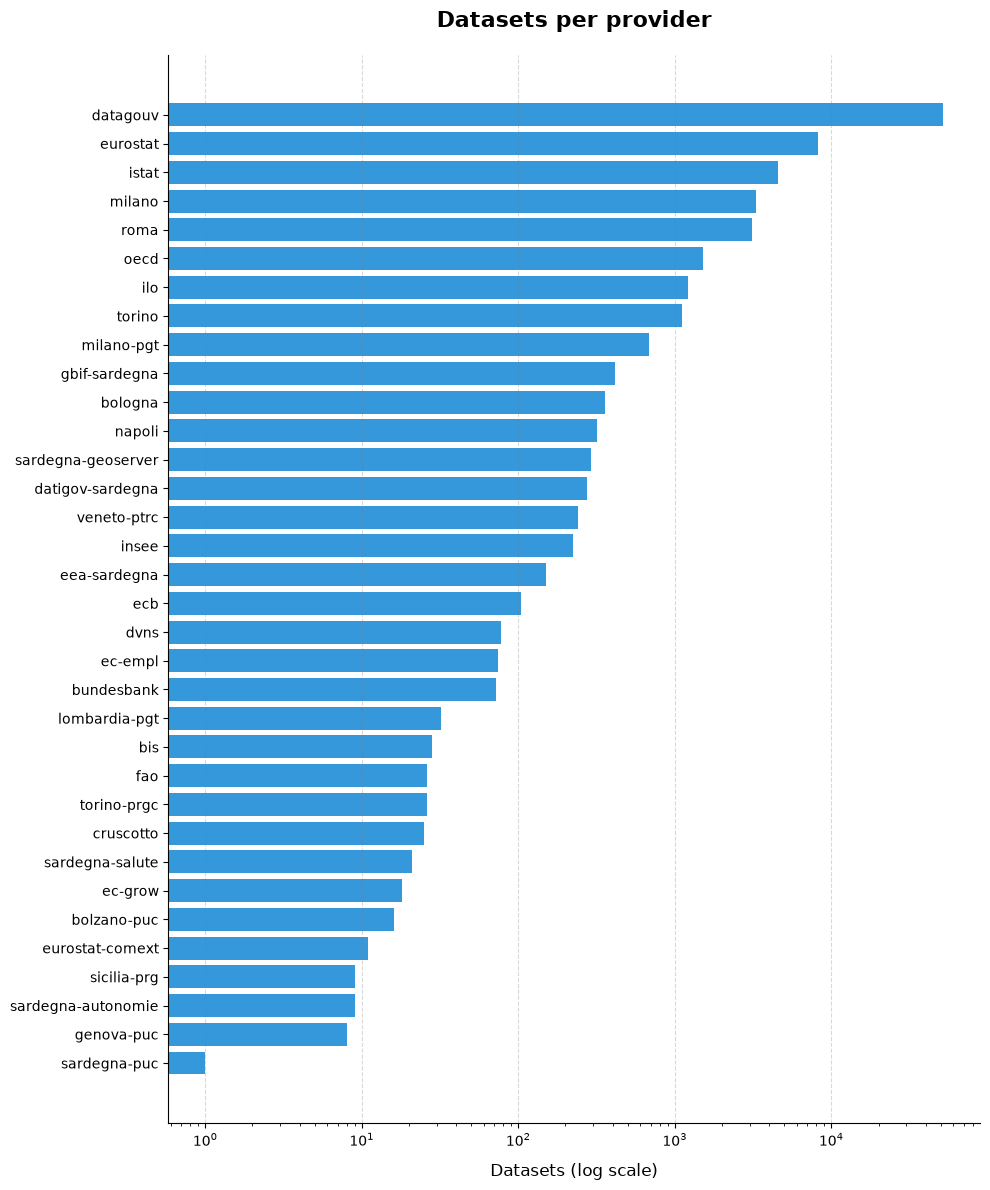

In [12]:
per_provider = con.sql(f"""
    SELECT provider, count(*) AS datasets
    FROM {table('opendata_catalog')}
    GROUP BY provider
    ORDER BY datasets
""").df()

plt.figure(figsize=(10, 12), dpi=100, facecolor="white")
plt.barh(per_provider["provider"], per_provider["datasets"], color="#3498db")
plt.xscale("log")
plt.title("Datasets per provider", fontsize=16, pad=20, fontweight="bold")
plt.xlabel("Datasets (log scale)", fontsize=12, labelpad=10)
plt.grid(True, axis="x", linestyle="--", alpha=0.3, color="gray")
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

The catalogue is multilingual: every dataset is described in the languages its provider publishes. The next chart counts the searchable descriptions per language.

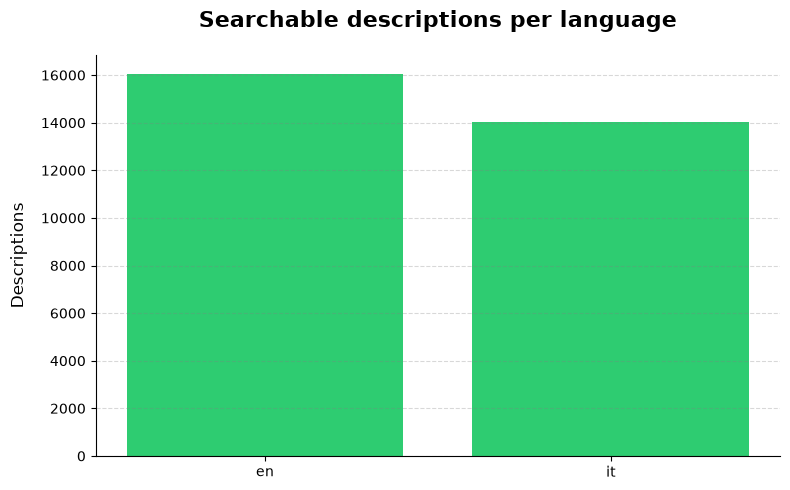

In [13]:
per_language = con.sql(f"""
    SELECT language, count(*) AS documents
    FROM {table('opendata_documents')}
    GROUP BY language
    ORDER BY documents DESC
""").df()

plt.figure(figsize=(8, 5), dpi=100, facecolor="white")
plt.bar(per_language["language"], per_language["documents"], color="#2ecc71")
plt.title("Searchable descriptions per language", fontsize=16, pad=20, fontweight="bold")
plt.ylabel("Descriptions", fontsize=12, labelpad=10)
plt.grid(True, axis="y", linestyle="--", alpha=0.3, color="gray")
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

### Q: What is one question that you have answered using these data? Can you show us how you came to that answer?

A question we answer every day with this catalogue: *where can I find data about a topic, from which providers, and under which terms may I reuse it?* Public data on one subject is scattered across statistical offices, national portals and city portals, each with its own catalogue and its own words.

Here we look for datasets about air quality. We search the English and Italian descriptions for the topic's words, then join the catalogue to show each dataset's provider, title, links and licence. A simple word match is enough to start; a real search would build an index over `opendata_documents` with an embedding model of the reader's choice, since the catalogue ships no vectors.

In [14]:
matches = con.sql(f"""
    SELECT c.provider, c.dataset_id, c.title, c.licence, c.sources
    FROM {table('opendata_documents')} d
    JOIN {table('opendata_catalog')} c USING (provider, dataset_id)
    WHERE (d.language = 'en' AND regexp_matches(lower(d.text), 'air quality|air pollution'))
       OR (d.language = 'it' AND regexp_matches(lower(d.text), 'qualità dell.aria|inquinamento atmosferico'))
    GROUP BY ALL
    ORDER BY c.provider, c.dataset_id
""").df()

print(len(matches), "datasets mention air quality")
matches.groupby("provider").size().sort_values(ascending=False)

143 datasets mention air quality


provider
milano                49
oecd                  32
istat                 30
eurostat              23
eea-sardegna           2
torino                 2
bologna                1
cruscotto              1
insee                  1
roma                   1
sardegna-geoserver     1
dtype: int64

In [15]:
# The licences these datasets are published under
matches["licence"].fillna("not declared by the provider").value_counts().head(10)

licence
https://w3id.org/italia/controlled-vocabulary/licences/A21_CCBY40    51
CC BY 4.0                                                            34
OECD Terms and Conditions                                            32
Eurostat reuse policy                                                23
Licence Ouverte / Open Licence 2.0                                    1
https://w3id.org/italia/controlled-vocabulary/licences/A29_IODL20     1
CC-BY 4.0                                                             1
Name: count, dtype: int64

In [16]:
# Where to read three of them: the provider's own links (deeper nested metadata folded as {...})
for row in matches.head(3).itertuples():
    print(row.provider, "|", row.title)
    pprint(json.loads(row.sources) if isinstance(row.sources, str) else row.sources, depth=2)
    print()

bologna | Zone limitazione velocità (30, 20, 10, 5 km/h)
[{'dataset_id': 'zone-30kmh-bologna',
  'dataset_uid': 'da_qzhur2',
  'metadata_url': 'https://opendata.comune.bologna.it/api/explore/v2.1/catalog/datasets/zone-30kmh-bologna',
  'native': {...},
  'role': 'catalogue',
  'url': 'https://opendata.comune.bologna.it/explore/dataset/zone-30kmh-bologna/'},
 {'acquisition': {...},
  'format': 'json',
  'resource_id': 'zone-30kmh-bologna',
  'role': 'distribution',
  'source_query_api': 'https://opendata.comune.bologna.it/api/explore/v2.1/catalog/datasets/zone-30kmh-bologna/records',
  'url': 'https://opendata.comune.bologna.it/api/explore/v2.1/catalog/datasets/zone-30kmh-bologna/exports/json'}]

cruscotto | Qualità dell'aria
[{'owner': 'ISPRA SNPA',
  'role': 'dataset',
  'url': 'https://www.isprambiente.gov.it/'},
 {'licence': 'CC BY 4.0',
  'rights_statement': None,
  'role': 'terms',
  'scope': 'provider-declared',
  'section': 'aria',
  'sha256': 'e736b8f2cb7908453ab65c57038da73d5a

### Q: What is one unanswered question that you think could be answered using these data? Do you have any recommendations or advice for someone wanting to answer this question?

**Which datasets of different providers measure the same thing for the same places?** ISTAT, Eurostat, the OECD and Italian cities often publish the same indicator (population, employment, waste, air quality) at different territorial levels, under different code lists and in different languages. The catalogue holds what is needed to link them: every dataset's dimensions (`opendata_structures`, `opendata_structure_dims`), every code with its labels in each language (`opendata_terms`), the codes that actually hold data (`opendata_held_codes`), and a searchable description per language (`opendata_documents`).

A crosswalk of equivalent datasets and code lists across providers would let anyone combine sources without reading every provider's catalogue. Some advice:

1. Start from the code lists, not the titles: territorial codes (NUTS, ISTAT municipality codes) and time periods are shared across providers and are a strong signal.
2. Compare labels across languages: `opendata_terms` names the same code in Italian, English, French, German and Spanish where providers publish them.
3. Use `opendata_held_codes` to keep only the combinations that hold data, so two datasets are linked only where they can actually be compared.
4. An open multilingual embedding model over `opendata_documents` is a good first pass for candidate pairs; the structures then confirm or reject them.